## First small models

### Imports

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import laspy
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils import resample, class_weight
from scipy.spatial import cKDTree
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from imblearn.over_sampling import SMOTE
import seaborn as sns
from collections import defaultdict
import matplotlib.pyplot as plt

### Load data from multiple files

In [6]:
# === List of file paths you want to combine ===
file_paths = [
    "C:/Users/flori/Desktop/pa-1_data/kantonal/zurich_10.laz",
    "C:/Users/flori/Desktop/pa-1_data/kantonal/zurich_11.laz",
    "C:/Users/flori/Desktop/pa-1_data/kantonal/zurich_12.laz",
    # Add more paths here
]

# === Prepare containers ===
all_features = []
all_labels = []

# === Create label map based on all files together ===
# (First pass to get all unique labels)
all_labels_raw = []
for path in file_paths:
    las_temp = laspy.read(path)
    all_labels_raw.extend(np.unique(las_temp.classification))

unique_labels = np.unique(all_labels_raw)
# Remove class 15
unique_labels = unique_labels[unique_labels != 15]

label_map = {label: idx for idx, label in enumerate(unique_labels)}
print("Label Map:", label_map)

# === Now actually load and process ===
for path in file_paths:
    las = laspy.read(path)

    # Info about each file
    print(f"\n--- File: {path} ---")
    print("Total points:", len(las.classification))
    print("Class distribution:\n", pd.Series(las.classification).value_counts())

    # Extract features
    ground_height = np.min(las.z)
    X = np.vstack((
        las.x,
        las.y,
        las.z,
        las.intensity,
        las.return_number,
        las.number_of_returns,
        las.z - ground_height,
        las.scan_angle
    )).T.astype(np.float32)

    y_raw = np.array(las.classification)

    # Remove points with class 15 (error class)
    mask_valid = (y_raw != 15)
    X = X[mask_valid]
    y_raw = y_raw[mask_valid]

    # map labels
    y_mapped = np.array([label_map[label] for label in y_raw])


    all_features.append(X)
    all_labels.append(y_mapped)

# === Stack everything together ===
X_combined = np.vstack(all_features)
y_combined = np.hstack(all_labels)

print("\n=== Combined dataset ===")
print("X shape:", X_combined.shape)
print("y shape:", y_combined.shape)

# === Standardize features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_combined)

# === Skip SMOTE for now ===
X_resampled, y_resampled = X_scaled, y_combined

# === Center each point cloud ===
N_POINTS = 1024
X_centered = X_resampled.copy()

for i in range(0, len(X_centered), N_POINTS):
    chunk = X_centered[i:i+N_POINTS]
    centroid = np.mean(chunk[:, :3], axis=0)
    X_centered[i:i+N_POINTS, :3] -= centroid


print("\n=== Final shapes after sampling ===")
print("X_sampled shape:", X_centered.shape)
print("y_sampled shape:", y_resampled.shape)

Label Map: {np.uint8(1): 0, np.uint8(2): 1, np.uint8(3): 2, np.uint8(4): 3, np.uint8(5): 4, np.uint8(6): 5, np.uint8(7): 6, np.uint8(17): 7}

--- File: C:/Users/flori/Desktop/pa-1_data/kantonal/zurich_10.laz ---
Total points: 8719136
Class distribution:
 2     4284521
6     3077079
5      851435
4      176527
1      142731
3       96945
7       79422
17      10476
Name: count, dtype: int64

--- File: C:/Users/flori/Desktop/pa-1_data/kantonal/zurich_11.laz ---
Total points: 6763967
Class distribution:
 2     3630647
6     2295033
1      288944
5      223703
3      120354
17     102983
4       82803
7       14167
15       5333
Name: count, dtype: int64

--- File: C:/Users/flori/Desktop/pa-1_data/kantonal/zurich_12.laz ---
Total points: 6344277
Class distribution:
 2     3479116
6     1604924
17     618695
1      382191
3      155665
5       43839
4       31926
15      20122
7        7799
Name: count, dtype: int64

=== Combined dataset ===
X shape: (21801925, 8)
y shape: (21801925,)

=== 

In [7]:
# Print class distribution
class_counts = pd.Series(y_resampled).value_counts().sort_index()
print("\nClass distribution (after combining all files):\n")
print(class_counts)


Class distribution (after combining all files):

0      813866
1    11394284
2      372964
3      291256
4     1118977
5     6977036
6      101388
7      732154
Name: count, dtype: int64


#### PointNet

In [21]:
# Parameters
N_POINTS = 1024
target_samples_per_class = 100_000  # adjust as needed

# Group points by class
class_indices = defaultdict(list)
for idx, label in enumerate(y_resampled):
    class_indices[label].append(idx)

# Balanced indices: keep all rare, limit common
balanced_indices = []
for label, indices in class_indices.items():
    if len(indices) <= target_samples_per_class:
        balanced_indices.extend(indices)
    else:
        balanced_indices.extend(np.random.choice(indices, target_samples_per_class, replace=False))

# Shuffle indices to mix
np.random.shuffle(balanced_indices)

# Get balanced X and y
X_balanced = X_centered[balanced_indices]
y_balanced = y_resampled[balanced_indices]

# Trim to fit full point clouds
num_samples = len(X_balanced) // N_POINTS
X_balanced = X_balanced[:num_samples * N_POINTS]
y_balanced = y_balanced[:num_samples * N_POINTS]

# Reshape into (num_clouds, 1024, features)
X_pointcloud = X_balanced.reshape(num_samples, N_POINTS, -1)
y_pointcloud = y_balanced.reshape(num_samples, N_POINTS)


In [22]:
def build_pointnet_model(num_points, num_features, num_classes):
    inputs = tf.keras.Input(shape=(num_points, num_features))

    # Per-point MLP (shared weights)
    x = layers.Conv1D(64, 1, activation='relu')(inputs)
    x = layers.Conv1D(128, 1, activation='relu')(x)
    x = layers.Conv1D(1024, 1, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    
    # Global feature (max pooling across points)
    global_feat = layers.GlobalMaxPooling1D()(x)
    
    # Repeat global features for each point
    global_feat = layers.RepeatVector(num_points)(global_feat)
    global_feat = layers.Concatenate()([x, global_feat])  # concat local + global

    # Bigger shared MLP
    x = layers.Conv1D(512, 1, activation='relu')(global_feat)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv1D(512, 1, activation='relu')(x)   
    x = layers.Dropout(0.3)(x)

    x = layers.Conv1D(256, 1, activation='relu')(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv1D(128, 1, activation='relu')(x)     
    x = layers.Dropout(0.3)(x) 

    # Output layer
    x = layers.Conv1D(num_classes, 1, activation='softmax')(x)

    model = models.Model(inputs=inputs, outputs=x)
    return model


In [23]:
NUM_CLASSES = len(np.unique(y_pointcloud))
model = build_pointnet_model(num_points=N_POINTS, num_features=X_pointcloud.shape[2], num_classes=NUM_CLASSES)

model.summary()

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
    metrics=['accuracy']
)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 1024, 8)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 1024, 64)  │        576 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_7 (Conv1D)   │ (None, 1024, 128) │      8,320 │ conv1d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_8 (Conv1D)   │ (None, 1024,      │    132,096 │ conv1d_7[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 1024,      │          0 │ conv1d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1024)      │          0 │ dropout_3[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector_1     │ (None, 1024,      │          0 │ global_max_pooli… │
│ (RepeatVector)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 1024,      │          0 │ dropout_3[0][0],  │
│ (Concatenate)       │ 2048)             │            │ repeat_vector_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_9 (Conv1D)   │ (None, 1024, 512) │  1,049,088 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 1024, 512) │          0 │ conv1d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_10 (Conv1D)  │ (None, 1024, 512) │    262,656 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 1024, 512) │          0 │ conv1d_10[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_11 (Conv1D)  │ (None, 1024, 256) │    131,328 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 1024, 256) │          0 │ conv1d_11[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_12 (Conv1D)  │ (None, 1024, 128) │     32,896 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 1024, 128) │          0 │ conv1d_12[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_13 (Conv1D)  │ (None, 1024, 8)   │      1,032 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,617,992 (6.17 MB)

 Trainable params: 1,617,992 (6.17 MB)

 Non-trainable params: 0 (0.00 B)

##### additional definitions before training

In [ ]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X_pointcloud, y_pointcloud, test_size=0.2, random_state=42)

# define callbacks
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)


In [ ]:
# Train
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=120,
    batch_size=64,
    callbacks=[reduce_lr, early_stop]
)

Epoch 1/120
10/10 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.1466 - loss: 2.0871 - val_accuracy: 0.3092 - val_loss: 1.9229 - learning_rate: 5.0000e-04
Epoch 2/120
10/10 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.2654 - loss: 1.8832 - val_accuracy: 0.3972 - val_loss: 1.6499 - learning_rate: 5.0000e-04
Epoch 3/120
10/10 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step - accuracy: 0.3730 - loss: 1.6539 - val_accuracy: 0.4373 - val_loss: 1.4818 - learning_rate: 5.0000e-04
Epoch 4/120
10/10 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.4480 - loss: 1.4915 - val_accuracy: 0.4914 - val_loss: 1.3428 - learning_rate: 5.0000e-04
Epoch 5/120
10/10 ━━━━━━━━━━━━━━━━━━━━ 28s 3s/step - accuracy: 0.4952 - loss: 1.3647 - val_accuracy: 0.5289 - val_loss: 1.2549 - learning_rate: 5.0000e-04
Epoch 6/120
10/10 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.5255 - loss: 1.2922 - val_accuracy: 0.5519 - val_loss: 1.2077 - learning_rate: 5.0000e-04
Epoch 7/120
10/10 ━━━━━━━━━━━━━━━━━━━━ 29s 3s/step - accuracy: 0.5453 

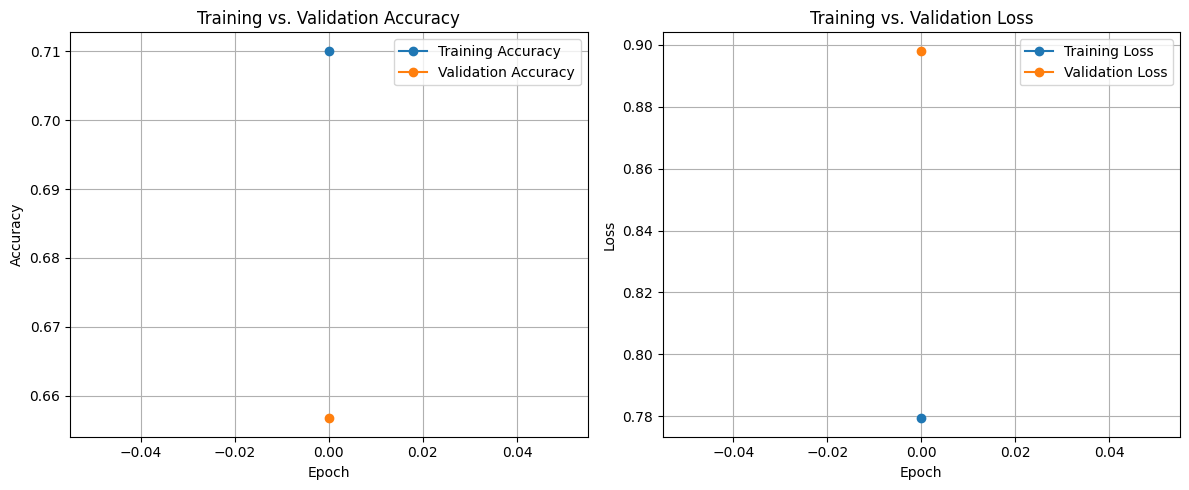

In [26]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Evaluation**

In [27]:
# Predict on test set
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=-1)

# Flatten for evaluation
y_true_flat = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

print("Accuracy:", accuracy_score(y_true_flat, y_pred_flat))
print(classification_report(y_true_flat, y_pred_flat))


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 264ms/step
Accuracy: 0.6567040704617835
              precision    recall  f1-score   support

           0       0.58      0.50      0.54     20127
           1       0.50      0.53      0.52     20149
           2       0.48      0.43      0.46     20101
           3       0.53      0.51      0.52     20072
           4       0.79      0.86      0.82     20329
           5       0.78      0.77      0.78     19929
           6       0.69      0.84      0.76     20089
           7       0.89      0.80      0.84     19972

    accuracy                           0.66    160768
   macro avg       0.65      0.66      0.65    160768
weighted avg       0.65      0.66      0.65    160768



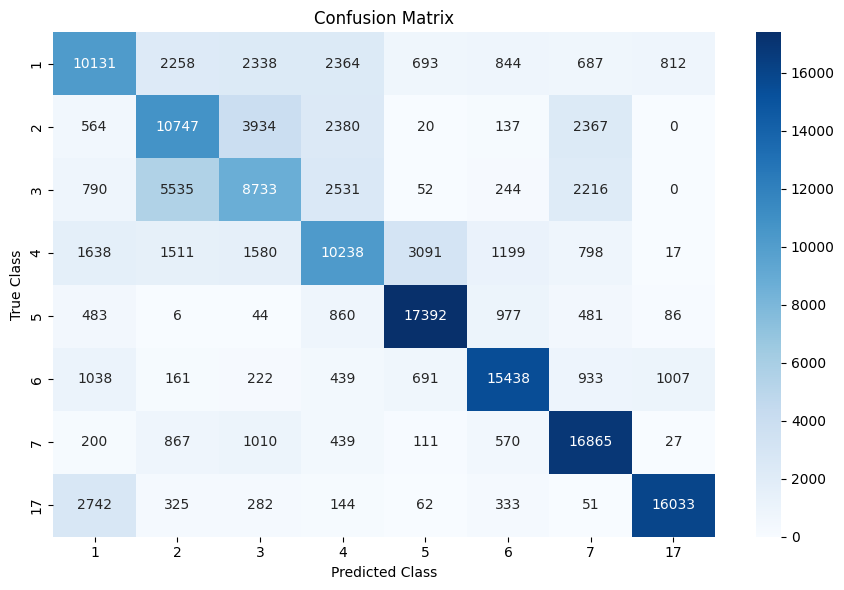

In [28]:
# Flatten labels
y_true = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

# Get inverse label map for display
inv_label_map = {v: k for k, v in label_map.items()}
labels = sorted(inv_label_map.keys())

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_flat, labels=labels)

# Plot
plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{inv_label_map[i]}" for i in labels],
            yticklabels=[f"{inv_label_map[i]}" for i in labels])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

##### test on unseen datafile

In [29]:
# === Load and inspect the new LAS file ===
path_flo_2 = "C:/Users/flori/Desktop/pa-1_data/kantonal/zurich_2.laz"
las_2 = laspy.read(path_flo_2)

print("New file classes:", np.unique(las_2.classification))

df2 = pd.DataFrame({
    "Classification": np.array(las_2.classification)
})

# Value count per class
display(df2["Classification"].value_counts())

# === Feature extraction ===
ground_height_2 = np.min(las_2.z)

X2 = np.vstack((
    las_2.x,
    las_2.y,
    las_2.z,
    las_2.intensity,
    las_2.return_number,
    las_2.number_of_returns,
    las_2.z - ground_height_2,
    las_2.scan_angle
)).T.astype(np.float32)

# === Label mapping ===
y2_raw = np.array(las_2.classification)
y2_mapped = np.array([label_map.get(label, -1) for label in y2_raw])  # unseen class (e.g. 15) → -1

# Filter out unseen labels
mask_known = y2_mapped != -1
X2 = X2[mask_known]
y2_mapped = y2_mapped[mask_known]

# === Normalize === (use same scaler from training)
X2_scaled = scaler.transform(X2)


New file classes: [ 1  2  3  4  5  6  7 17]


Classification
2     3606443
6     2312505
5      823094
4      197726
1      137979
3       48155
7        9758
17       7138
Name: count, dtype: int64

In [30]:
# === Reshape to mini point clouds ===
N_POINTS = 1024
NUM_SAMPLES = len(X2_scaled) // N_POINTS

X2_trimmed = X2_scaled[:NUM_SAMPLES * N_POINTS]
y2_trimmed = y2_mapped[:NUM_SAMPLES * N_POINTS]

X2_pointcloud = X2_trimmed.reshape(NUM_SAMPLES, N_POINTS, -1)
y2_pointcloud = y2_trimmed.reshape(NUM_SAMPLES, N_POINTS)

# === Center each point cloud to origin ===
X2_pointcloud[:, :, :3] -= np.mean(X2_pointcloud[:, :, :3], axis=1, keepdims=True)


# === Predict ===
y2_pred_probs = model.predict(X2_pointcloud)
y2_pred_labels = np.argmax(y2_pred_probs, axis=-1)

# === Flatten and evaluate ===
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y2_true_flat = y2_pointcloud.flatten()
y2_pred_flat = y2_pred_labels.flatten()

print("Accuracy on new file:", accuracy_score(y2_true_flat, y2_pred_flat))
print(classification_report(y2_true_flat, y2_pred_flat))


218/218 ━━━━━━━━━━━━━━━━━━━━ 72s 329ms/step
Accuracy on new file: 0.1513555667562724
              precision    recall  f1-score   support

           0       0.02      0.22      0.04    137979
           1       0.61      0.01      0.01   3606222
           2       0.03      0.04      0.03     48143
           3       0.07      0.01      0.02    197688
           4       0.82      0.17      0.29    822967
           5       0.26      0.38      0.31   2312505
           6       0.00      0.47      0.00      9758
           7       0.00      0.00      0.00      7138

    accuracy                           0.15   7142400
   macro avg       0.23      0.16      0.09   7142400
weighted avg       0.49      0.15      0.14   7142400



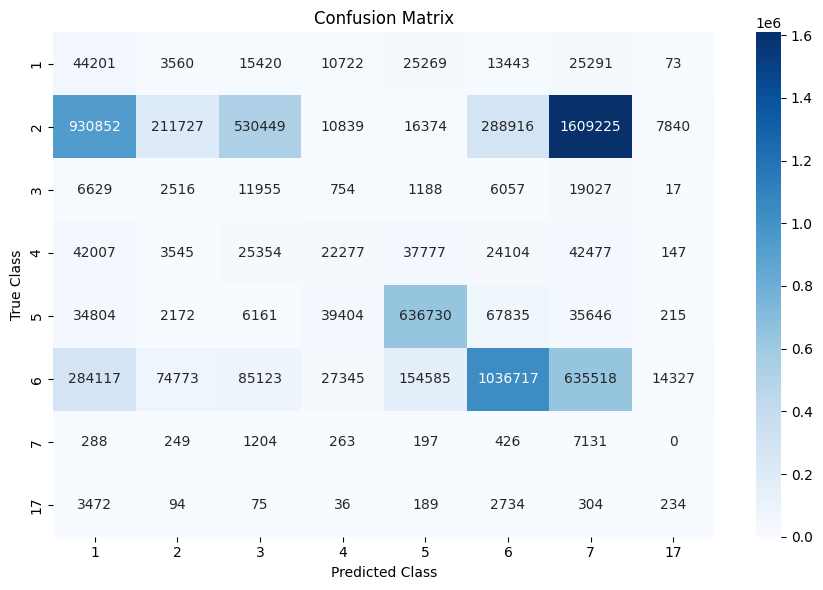

In [20]:
# Flatten labels
y2_true = y2_true_flat
y2_pred_flat = y2_pred_labels.flatten()

# Get inverse label map for display
inv_label_map = {v: k for k, v in label_map.items()}
labels = sorted(inv_label_map.keys())

# Compute confusion matrix
cm = confusion_matrix(y2_true, y2_pred_flat, labels=labels)

# Plot
plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{inv_label_map[i]}" for i in labels],
            yticklabels=[f"{inv_label_map[i]}" for i in labels])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

### Basic PointNet++ Model

In [5]:
# === Imports and Model Definition ===

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import laspy
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset


class PointNetSetAbstraction(nn.Module):
    def __init__(self, in_channels, mlp_layers):
        super(PointNetSetAbstraction, self).__init__()
        layers = []
        last_channel = in_channels
        for out_channel in mlp_layers:
            layers.append(nn.Conv1d(last_channel, out_channel, kernel_size=1))
            layers.append(nn.BatchNorm1d(out_channel))
            layers.append(nn.ReLU())
            last_channel = out_channel
        self.mlp = nn.Sequential(*layers)

    def forward(self, x):
        return self.mlp(x)

class PointNetPlusPlus(nn.Module):
    def __init__(self, num_classes):
        super(PointNetPlusPlus, self).__init__()
        self.sa1 = PointNetSetAbstraction(6, [64, 128, 256])
        self.sa2 = PointNetSetAbstraction(256, [256, 512, 1024])
        self.fc1 = nn.Linear(1024, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, num_classes)
        self.dropout = nn.Dropout(p=0.3)
        
    def forward(self, x):
        x = self.sa1(x)
        x = self.sa2(x)
        x = torch.max(x, 2)[0]  # Global max pooling
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x




In [14]:
# === Load and Preprocess LAS File ===

las = laspy.read(path_flo)

ground_height = np.min(las.z)

X = np.vstack((
    las.x, 
    las.y, 
    las.z, 
    las.intensity, 
    las.return_number,  
    las.z - ground_height  
)).T.astype(np.float32)  

unique_labels = np.unique(las.classification)
label_map = {label: idx for idx, label in enumerate(unique_labels)}
y = np.array([label_map[label] for label in las.classification]).astype(np.int64)

sample_indices = np.random.choice(X.shape[0], size=50000, replace=False)
X = X[sample_indices]
y = y[sample_indices]

scaler = StandardScaler()
X = scaler.fit_transform(X)

# Convert to PyTorch tensors
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train, dtype=torch.float32)  # Keep original shape
X_test = torch.tensor(X_test, dtype=torch.float32)  
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16)

In [ ]:
# === Train PointNet++ Model ===

from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PointNetPlusPlus(num_classes=len(unique_labels)).to(device)
X_train, X_test, y_train, y_test = X_train.to(device), X_test.to(device), y_train.to(device), y_test.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

num_epochs = 30

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
        X_batch, y_batch = batch
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Reshape input to (batch_size, num_features, num_points)
        X_batch = X_batch.unsqueeze(2)  # Add a dummy dimension for num_points

        optimizer.zero_grad()
        outputs = model(X_batch)  # Now correctly shaped
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {total_loss:.4f}")

    # Reduce Learning Rate after 20 epochs
    if epoch == 15:
        for param_group in optimizer.param_groups:
            param_group['lr'] = 0.0001

Epoch 1/30:   0%|          | 0/2500 [00:00<?, ?it/s]

Epoch 1/30: 100%|██████████| 2500/2500 [02:41<00:00, 15.43it/s]


Epoch [1/30], Loss: 1980.4978


Epoch 2/30: 100%|██████████| 2500/2500 [02:47<00:00, 14.96it/s]


Epoch [2/30], Loss: 1788.0371


...

Epoch [28/30], Loss: 1349.8530


Epoch 29/30: 100%|██████████| 2500/2500 [02:54<00:00, 14.34it/s]


Epoch [29/30], Loss: 1353.4645


Epoch 30/30: 100%|██████████| 2500/2500 [02:47<00:00, 14.89it/s]

Epoch [30/30], Loss: 1363.0135


In [17]:
# === Evaluate PointNet++ Model ===

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for batch in test_loader:
        X_batch, y_batch = batch
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Ensure correct shape (batch_size, num_features, num_points)
        X_batch = X_batch.unsqueeze(2)  # Add a dummy dimension for num_points
        
        outputs = model(X_batch)  # Pass correctly shaped input
        predicted = torch.argmax(outputs, dim=1)
        correct += (predicted == y_batch).sum().item()
        total += y_batch.size(0)

print(f"Test Accuracy: {correct / total:.4f}")


Test Accuracy: 0.7559


#### Evaluation
Model is more accurate than the very first PyTorch model but is much too slow for our amount of datapoints
Maybe with HPC this could be a promising option